In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
import numpy as np
import matplotlib.dates as mdates
import plotly.express as px

df = pd.read_csv('applicants_cleaned.csv', parse_dates=['Application Date'])
     

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    77 non-null     object        
 1   Email             66 non-null     object        
 2   Phone             74 non-null     object        
 3   Domain Applied    77 non-null     object        
 4   University        67 non-null     object        
 5   Application Date  77 non-null     datetime64[ns]
 6   Status            69 non-null     object        
dtypes: datetime64[ns](1), object(6)
memory usage: 4.3+ KB


In [25]:
df.head()

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Omar Hassan,omar.hassan1@example.com,010-85329037,artificial intelligence,AUC,2025-08-19,Under Review
1,Nour Khaled,nour.khaled2@example.com,010-38898923,web dev,AUC,2025-06-28,NaN
2,Sara Ali,sara.ali3@example.com,011-20576383,Cyber Security,BUE,2025-12-03,Selected
3,Omar Hassan,omar.hassan4@example.com,011-47308985,WEB DEV,BUE,2026-04-22,under review
4,Nour Khaled,nour.khaled5@example.com,011-60929647,Cybersecurity,NaN,2025-11-11,Selected


In [27]:
""""
The goal of this analysis is to explore the NextGenLearners applicant dataset, identify patterns, and communicate findings through summary statistics and visualizations.

Each analysis will follow three steps:
1. Ask a clear question about the data.
2. Answer it using Python and Pandas.
3. Visualize the results and write a short takeaway.
"""

'"\nThe goal of this analysis is to explore the NextGenLearners applicant dataset, identify patterns, and communicate findings through summary statistics and visualizations.\n\nEach analysis will follow three steps:\n1. Ask a clear question about the data.\n2. Answer it using Python and Pandas.\n3. Visualize the results and write a short takeaway.\n'

In [29]:
df['Domain Applied'].value_counts()

Domain Applied
web dev                    11
Web Development             7
DATA SCIENCE                7
data science                7
artificial intelligence     5
Cyber Security              5
UI UX                       5
Artificial Intelligence     5
WEB DEV                     4
Data Science                4
ui/ux                       4
UI/UX                       4
cyber security              4
AI                          3
Cybersecurity               2
Name: count, dtype: int64

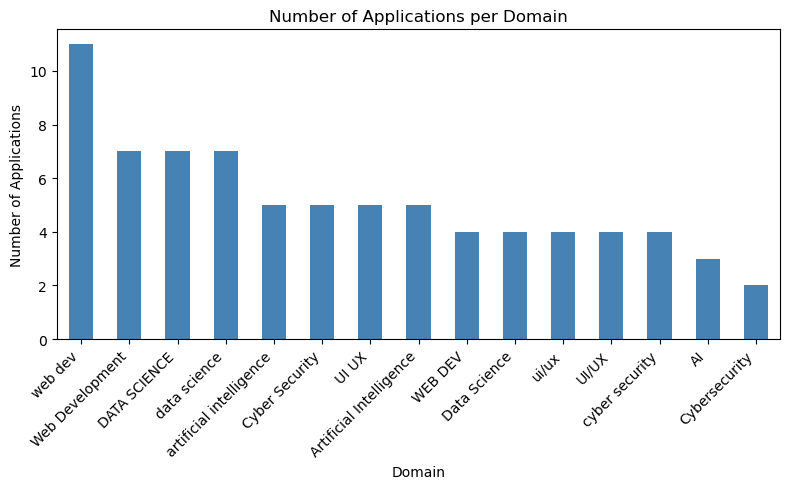

In [31]:
# Count applications for each domain and plot the results
df['Domain Applied'].value_counts().plot.bar(
    figsize=(8, 5),
    color='steelblue'
)

plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
# Takeaway: Web Development received the highest number of applications (21),
# while Cyber Security received the lowest number (11).

In [33]:
# Extract the month from each application date
df['Application Month'] = df['Application Date'].dt.to_period('M')

# Count applications in each month
monthly_trend = df.groupby('Application Month').size()

# Display the monthly application counts
print(monthly_trend)

Application Month
2025-01    3
2025-02    4
2025-03    2
2025-04    5
2025-05    4
2025-06    4
2025-07    4
2025-08    4
2025-09    3
2025-10    1
2025-11    2
2025-12    3
2026-01    2
2026-02    1
2026-03    5
2026-04    3
2026-05    5
2026-06    2
2026-07    4
2026-08    8
2026-09    3
2026-10    2
2026-11    3
Freq: M, dtype: int64


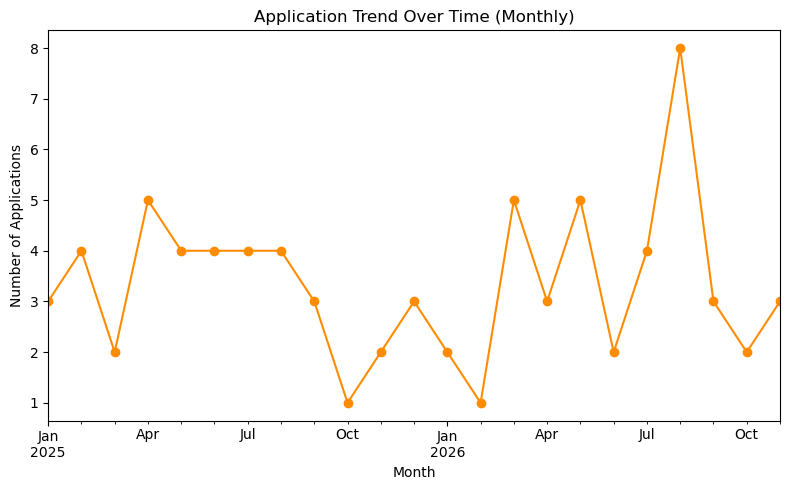

In [35]:
# Plot the monthly application trend
monthly_trend.plot(
    kind='line',
    marker='o',
    color='darkorange',
    figsize=(8, 5)
)

# Add chart title and axis labels
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')

plt.tight_layout()
plt.show()

# Takeaway: Applications peaked in August 2026 with 8 applications.

In [37]:
# Count applicants by application status
df['Status'].value_counts()

Status
UNDER REVIEW    11
rejected        10
Under Review     8
REJECTED         8
Selected         7
Rejected         7
SELECTED         7
under review     6
selected         5
Name: count, dtype: int64

In [39]:
# Count applicants by domain and status
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)

# Display the results
print(status_by_domain)

Status                   REJECTED  Rejected  SELECTED  Selected  UNDER REVIEW  \
Domain Applied                                                                  
AI                              0         0         1         0             0   
Artificial Intelligence         0         1         0         0             1   
Cyber Security                  1         0         0         1             1   
Cybersecurity                   0         0         0         1             0   
DATA SCIENCE                    1         0         1         0             1   
Data Science                    0         0         0         1             0   
UI UX                           2         0         1         0             1   
UI/UX                           0         1         1         0             1   
WEB DEV                         0         1         0         0             0   
Web Development                 0         0         1         3             0   
artificial intelligence     

In [41]:
# Calculate the percentage of each status within each domain
status_by_domain_pct = (
    status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100
)

# Display percentages rounded to one decimal place
print(status_by_domain_pct.round(1))

Status                   REJECTED  Rejected  SELECTED  Selected  UNDER REVIEW  \
Domain Applied                                                                  
AI                            0.0       0.0      50.0       0.0           0.0   
Artificial Intelligence       0.0      25.0       0.0       0.0          25.0   
Cyber Security               20.0       0.0       0.0      20.0          20.0   
Cybersecurity                 0.0       0.0       0.0      50.0           0.0   
DATA SCIENCE                 20.0       0.0      20.0       0.0          20.0   
Data Science                  0.0       0.0       0.0      25.0           0.0   
UI UX                        40.0       0.0      20.0       0.0          20.0   
UI/UX                         0.0      33.3      33.3       0.0          33.3   
WEB DEV                       0.0      25.0       0.0       0.0           0.0   
Web Development               0.0       0.0      14.3      42.9           0.0   
artificial intelligence     

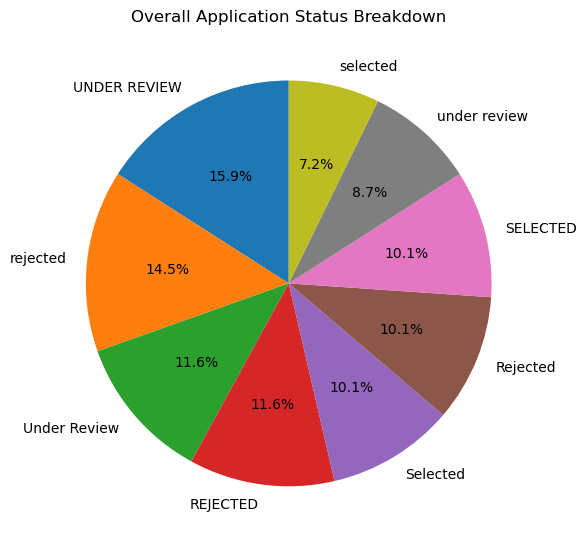

In [43]:
df['Status'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    figsize=(6, 6)
)

# Add chart title and remove the default y-axis label
plt.title('Overall Application Status Breakdown')
plt.ylabel('')

plt.tight_layout()
plt.show()

# Takeaway: Under Review is the largest status group,
# followed by Rejected and then Selected.

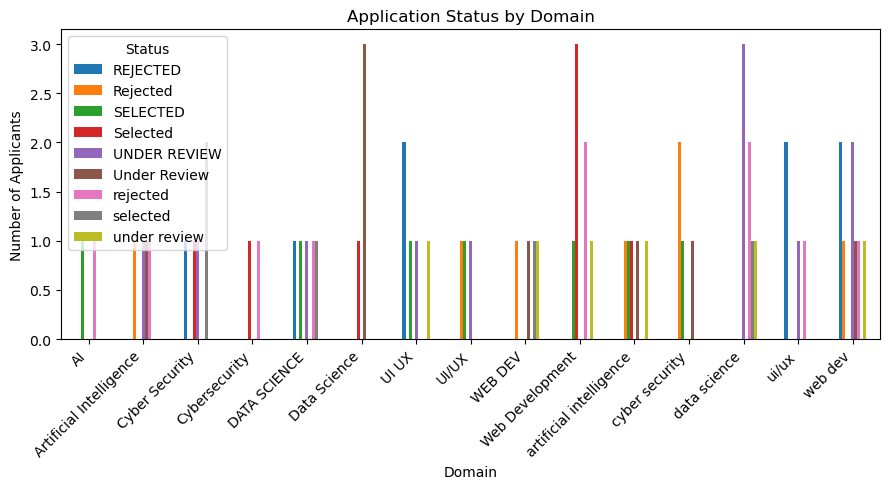

In [45]:

# Plot application status counts for each domain
pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
).plot(kind='bar', figsize=(9, 5))

# Add chart title and axis labels
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')

# Rotate domain labels and add a legend
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')

plt.tight_layout()
plt.show()

# Takeaway: Cyber Security has the highest number of selected applicants (5),
# while Web Development has the highest number of applicants under review (10).

In [47]:
# Count applicants from each university and select the top 10
df['University'].value_counts().head(10)

University
Zagazig University       14
BUE                      10
AUC                       9
Helwan Univ.              8
Ain Shams University      6
Cairo University          6
Helwan University         6
Alexandria University     5
Mansoura University       3
Name: count, dtype: int64

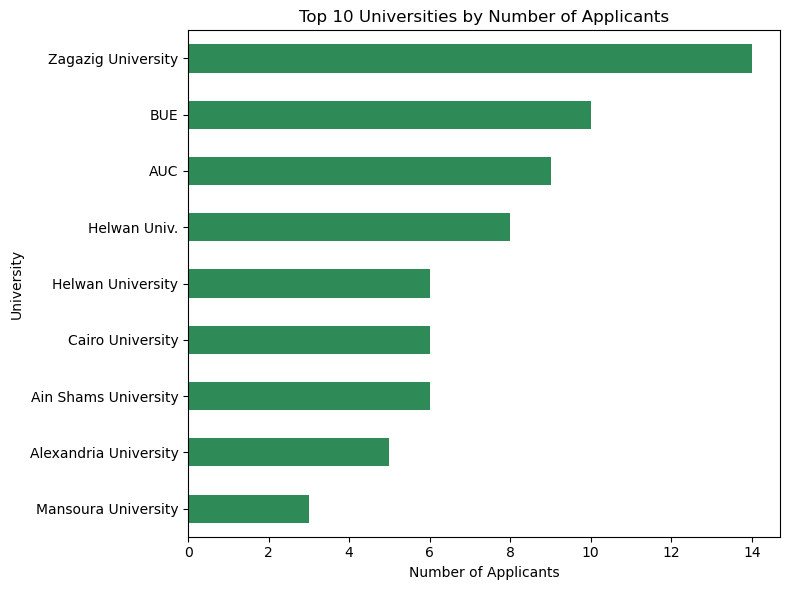

In [49]:

# Count applicants from each university and select the top 10
df['University'].value_counts().head(10).sort_values().plot.barh(
    figsize=(8, 6),
    color='seagreen'
)

# Add chart title and axis labels
plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')

plt.tight_layout()
plt.show()

# Takeaway: Zagazig University contributed the highest number of applicants (14).
# Note: "Not Specified" represents applicants whose university was not specified.

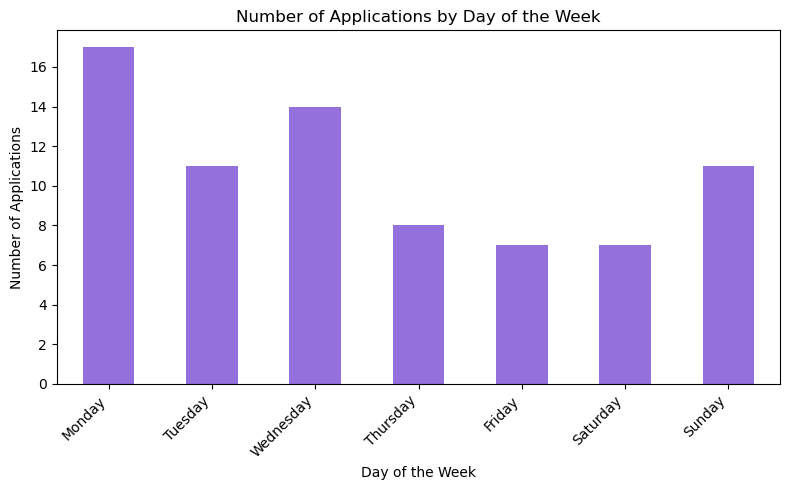

In [33]:
# Count applications by day of the week
df['Application Date'].dt.day_name().value_counts().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
     'Friday', 'Saturday', 'Sunday'],
    fill_value=0
).plot.bar(figsize=(8, 5), color='mediumpurple')

# Add chart title and axis labels
plt.title('Number of Applications by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Applications')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Reason: This chart helps explore whether application activity
# differs across weekdays and weekends.

In [35]:

# Key Insights

# 1. Web Development received the highest number of applications (21),
# while Cyber Security received the lowest number (11).

# 2. Applications peaked in August 2026, with 8 applications in that month.

# 3. Cyber Security had the highest selection rate among the five domains,
# at 45.5% (5 out of 11 applicants).

# 4. UI/UX had the highest rejection rate, at 46.2% (6 out of 13 applicants).

# 5. Zagazig University contributed the highest number of applicants (14).